# Seaborn İleri Düzey

Bu derste çok değişkenli keşfin araçlarını öğreniyorsun: ısı haritasıyla korelasyon haritası çıkarmak, pairplot'la tüm değişken çiftlerini tek bakışta görmek, jointplot'la iki değişkenin dağılımını ve ilişkisini birlikte incelemek ve facet'lerle aynı grafiği alt gruplarda tekrarlamak. 6. dersin EDA'sı sayılarla yapıyordu; bugün onu görselle yapıyoruz.

## 🎯 Bu Derste Ne Öğreneceğiz?

Bu dersin sonunda şunları yapabileceksin:

- Korelasyon matrisini hesaplayıp ısı haritasıyla okumak
- `pairplot` ile sayısal değişken çiftlerinin tamamını tek figürde görmek
- `jointplot` ile iki değişkenin ilişkisini ve dağılımlarını birlikte göstermek
- `catplot` ve `relplot` ile kategori bazlı facet (alt panel) grafikleri kurmak
- Çok değişkenli grafikleri kalabalığa boğmadan kullanmak

Bu ders, kursun 7. öğrenme çıktısını tamamlıyor ve 10. çıktısına (grafik eleştirisi ve iyileştirme) hizmet ediyor.

## 💡 Neden Bu Konuyu Öğreniyoruz?

Elimizde artık beş sayısal değişkenli bir tablo var: öğrencilerin haftalık çalışma saati, uyku saati, sosyal medya saati, kahve tüketimi ve vize notu. "Notu ne belirliyor?" gibi bir soru, değişken çiftlerinin **hepsini** aynı anda görmeyi gerektirir. Tek tek scatter çizmek 20 grafik demektir; seaborn bu keşfi matris grafiğiyle (pairplot), özetle (korelasyon ısı haritası) ve alt panellerle (facet) üç kılıkta yapmamızı sağlar.

Ama güçlü araçların bedeli vardır: her şeyi tek grafikte gösterme isteği, 1. dersin "kalabalık grafik" hatasına götürür. Bu dersin ikinci teması budur: neyi göstereceğine karar vermek.

## 🔗 Ön Bilgi

- [Seaborn Temelleri](09-Seaborn-Basics.ipynb): `data`/`x`/`y`/`hue` arayüzü, histogram, kutu ve çubuk grafikler.
- [Veri Temizleme ve Keşfedici Analiz](06-Data-Cleaning.ipynb): EDA zihniyeti.
- [Grafik Türleri ve Doğru Seçim](02-Chart-Types.ipynb): ısı haritasının "kesişim" sorusu ve sıralı paletler.

## 🔍 Birlikte Keşfedelim

Veri seti: bir üniversitedeki 60 öğrencinin alışkanlıkları (`../Data/10-student-habits.csv`). Yüklemeden önce tabloyu tanıyalım:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

ogrenci = pd.read_csv("../Data/10-student-habits.csv")
ogrenci.head()

,ogrenci_id,bolum,calisma_saati,uyku_saati,sosyal_medya_saati,kahve_fincan,vize_notu
0,1,İşletme,6.0,6.4,5.4,5.9,52.1
1,2,Psikoloji,8.0,9.3,0.5,8.9,71.8
2,3,Bilgisayar,3.4,7.9,2.0,2.7,48.3
3,4,İşletme,5.4,6.1,6.0,3.6,42.7
4,5,Psikoloji,2.7,7.1,1.4,3.6,47.0


**Tahminin:** Vize notunu en çok hangi değişken etkiliyor olabilir: çalışma saati, uyku saati, sosyal medya saati yoksa kahve tüketimi mi? Sıralama tahminini bu hücreye yaz. Sonra ısı haritasına bakıp kendini kontrol edeceğiz.

Korelasyon matrisini hesaplayıp çizelim:

In [2]:
kor = ogrenci.corr(numeric_only=True)
kor.round(2)

,ogrenci_id,calisma_saati,uyku_saati,sosyal_medya_saati,kahve_fincan,vize_notu
ogrenci_id,1.00,0.05,-0.03,0.11,0.07,0.09
calisma_saati,0.05,1.00,-0.11,0.06,0.91,0.86
uyku_saati,-0.03,-0.11,1.00,-0.66,-0.05,0.02
sosyal_medya_saati,0.11,0.06,-0.66,1.00,-0.04,-0.17
kahve_fincan,0.07,0.91,-0.05,-0.04,1.00,0.79
vize_notu,0.09,0.86,0.02,-0.17,0.79,1.00


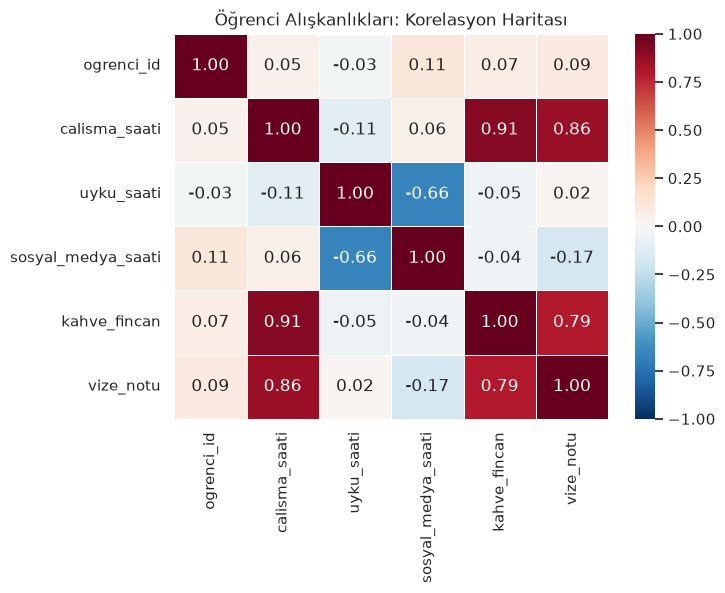

In [3]:
plt.figure(figsize=(7, 5))
sns.heatmap(kor, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            fmt=".2f", linewidths=0.5)
plt.title("Öğrenci Alışkanlıkları: Korelasyon Haritası")
plt.show()

**Gözlem:** Tabloyu okuma kuralı: hücreler değişken çiftlerinin korelasyonunu (ilişki ölçüsünü) taşıyor; +1'e yakın mavi = birlikte artıyor, -1'e yakın kırmızı = biri artarken azalıyor, 0 = ilişki yok. Tahminin tuttu mu? Büyük olasılıkla şu üç bulgu seni yakaladı:

- `calisma_saati` ile `vize_notu` arasında **güçlü pozitif** ilişki (yaklaşık 0.86): çok çalışan yüksek alıyor.
- `kahve_fincan` ile `vize_notu` arasında da **güçlü pozitif** ilişki var! Kahve notu yükseltiyor mu?
- `uyku_saati` neredeyse her şeyle ilgisiz görünüyor.

İkinci madde bu dersin en önemli dersidir: **ilişki, neden değildir.** Kahve içmek notu yükseltmiyor; kahve tüketimi çalışan öğrencilerde yüksek (matriste `kahve_fincan`-`calisma_saati` ilişkisi bunu açıklıyor). Korelasyon haritası "birlikte hareket edenler" listesi verir; nedeni vermez. 7. dersteki reklam-satış grafiğinde de aynı uyarıyı görmüştük.

## 📖 Kavramlar

**Korelasyon (correlation):** İki sayısal değişkenin birlikte değişme derecesi, -1 ile +1 arası tek sayıyla özetlenir. Yön (pozitif/negatif) ve güç (0'a yakın/±1'e yakın) okunur. Nedensellik söylemez.

**Isı haritası:** Kesişim tablosunu renkle kodlar. Korelasyon matrisi için **ayrışan (diverging)** palet kullanılır (`RdBu_r` gibi): orta değer (0) nötr renk, iki uç zıt renk. `center=0` ortayı sabitler; `annot=True` hücrelere sayı yazar. 2. dersteki sıralı palet burada yanlış seçim olurdu: sıralı palet "daha çok = daha koyu" der, korelasyonda ise iki zıt yön vardır.

**pairplot:** Tüm sayısal sütun çiftlerinin scatter matrisi; diyagonalde her değişkenin kendi dağılımı (`diag_kind="kde"` ile yoğunluk eğrisi). `hue` ile kategoriler renklenir. Değişken sayısı arttıkça büyür; 5-6 değişken üstünde `corner=True` veya alt küme seçmek gerekir.

**jointplot:** İki değişkenin scatter'ı + kenarlarda her ikisinin tek değişkenli dağılımı. `kind="reg"` üzerine eğilim çizgisi de ekler.

**Facet (alt panel):** Aynı grafik türünü bir kategorinin her değeri için tekrarlamak (`relplot`/`catplot` ile `col=`/`row=`). "Küçük çoklular" olarak da bilinir; kalabalık tek grafiği bölmek için en güçlü çözümdür.

## 🛠️ Uygulama

### 1) pairplot: tüm çiftler tek figürde

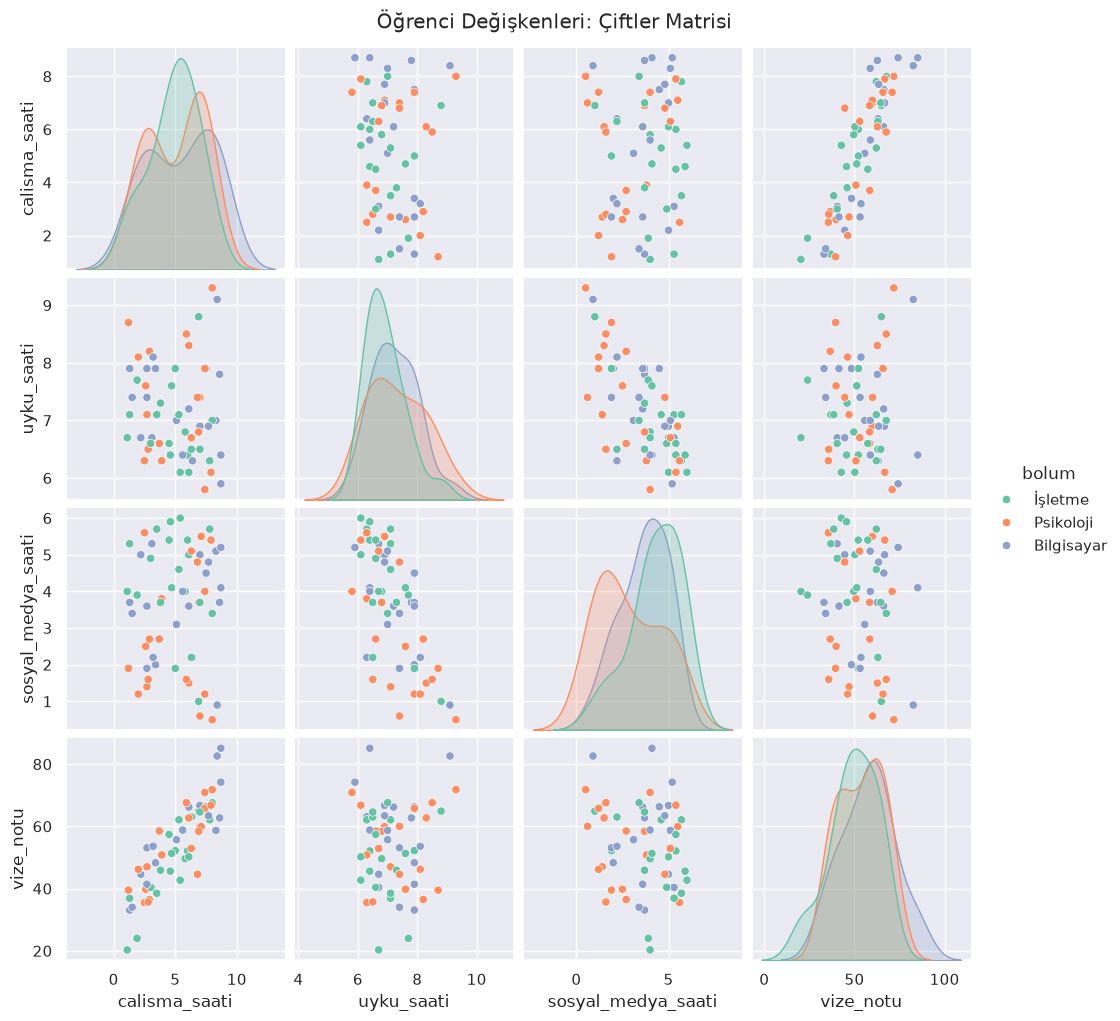

In [4]:
sns.pairplot(ogrenci, vars=["calisma_saati", "uyku_saati",
                            "sosyal_medya_saati", "vize_notu"],
             hue="bolum", diag_kind="kde", palette="Set2")
plt.suptitle("Öğrenci Değişkenleri: Çiftler Matrisi", y=1.02)
plt.show()

Matrisi okuma: satır ve sütunlar aynı değişkenler; (i, j) hücresi i. değişkeni y, j. değişkeni x eksenine koyar. Diyagonal kendi dağılımıdır. En çarpık panel: `calisma_saati`-`vize_notu` scatter'ı — sağa yükselen belirgin eğilim. Renkler bölümleri ayırıyor; dağılımların bölümlere göre kaydığı yerler de ipucu taşır. `vars=[...]` ile sütun alt kümesi seçtik (id ve kahve dışarıda kaldı); `corner=True` ekleyerek yalnızca alt üçgeni çizmesini de isteyebilirdik.

### 2) jointplot: ilişki + kenar dağılımları

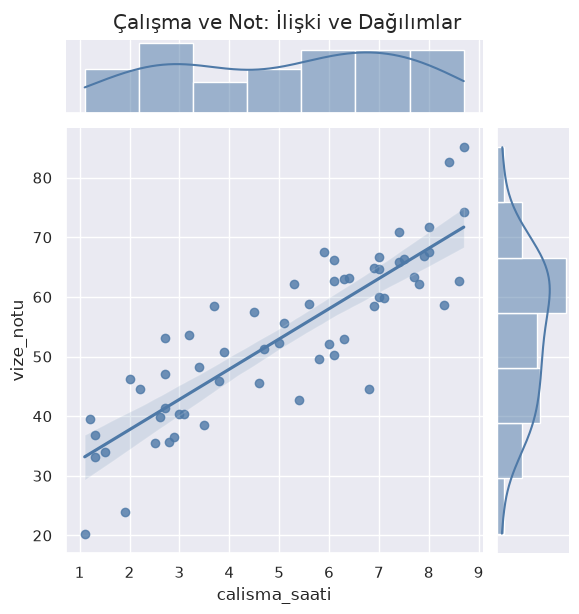

In [5]:
sns.jointplot(data=ogrenci, x="calisma_saati", y="vize_notu",
              kind="reg", color="#4e79a7", height=6)
plt.suptitle("Çalışma ve Not: İlişki ve Dağılımlar", y=1.02)
plt.show()

Ortadaki panel 9. dersteki scatter; üstte ve sağda her iki değişkenin histogramı; `kind="reg"` ile üzerine eğilim doğrusu ve etrafına belirsizlik bandı eklendi. Tek grafikte "ilişki var mı, veri nerede yığılı?" sorusunun ikisine de cevap var.

### 3) catplot: kategorik facet'ler

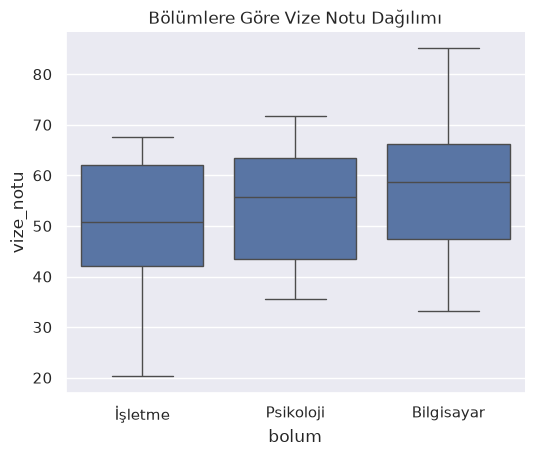

In [6]:
sns.catplot(data=ogrenci, x="bolum", y="vize_notu",
            kind="box", height=4.5, aspect=1.2)
plt.title("Bölümlere Göre Vize Notu Dağılımı")
plt.show()

`catplot` bir "fabrika" fonksiyonudur: `kind` ile kutu, keman, çubuk, nokta grafiği üretir. Asıl gücü facet parametrelerinde:

In [7]:
sns.catplot(data=ogrenci, x="bolum", y="vize_notu",
            col="sosyal_medya_kesim", height=4, aspect=1.1)
plt.show()

ValueError: Could not interpret value `sosyal_medya_kesim` for `col`. An entry with this name does not appear in `data`.

Bu hücre çalışmayacak — bilerek! `sosyal_medya_kesim` diye bir sütun yok. Kategorik bir değişkeni bölmek için önce onu türetmemiz gerekir (5. dersten sütun türetme):

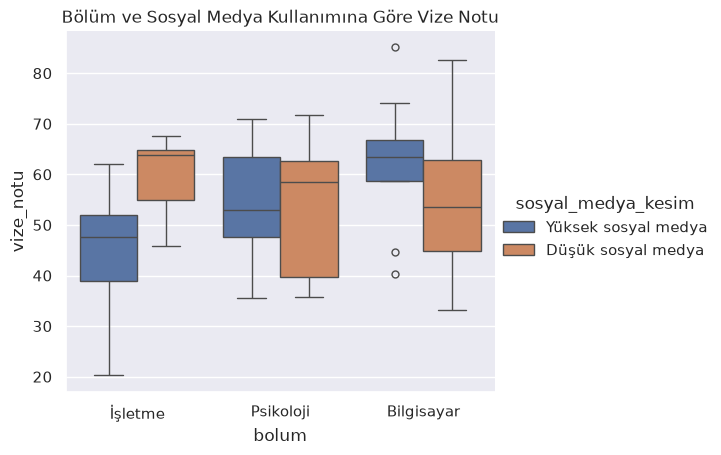

In [8]:
# Sosyal medya kullanımını ikiye böl: düşük / yüksek (medyan üstü)
esik = ogrenci["sosyal_medya_saati"].median()
ogrenci["sosyal_medya_kesim"] = (
    ogrenci["sosyal_medya_saati"] > esik
).map({True: "Yüksek sosyal medya", False: "Düşük sosyal medya"})

sns.catplot(data=ogrenci, x="bolum", y="vize_notu",
            hue="sosyal_medya_kesim", kind="box", height=4.5, aspect=1.2)
plt.title("Bölüm ve Sosyal Medya Kullanımına Göre Vize Notu")
plt.show()

**Gözlem:** Her panelde iki kutu karşılaştırılıyor: düşük ve yüksek sosyal medya kullanan öğrenciler. Genel desen: yüksek sosyal medya grubunda notlar biraz daha düşük — korelasyon haritasındaki -0.17'nin görsel karşılığı. `hue` burada bir karşılaştırma ekseni, `col`/`row` ise panelleri açan boyut olurdu.

### 4) relplot ile küçük çoklular

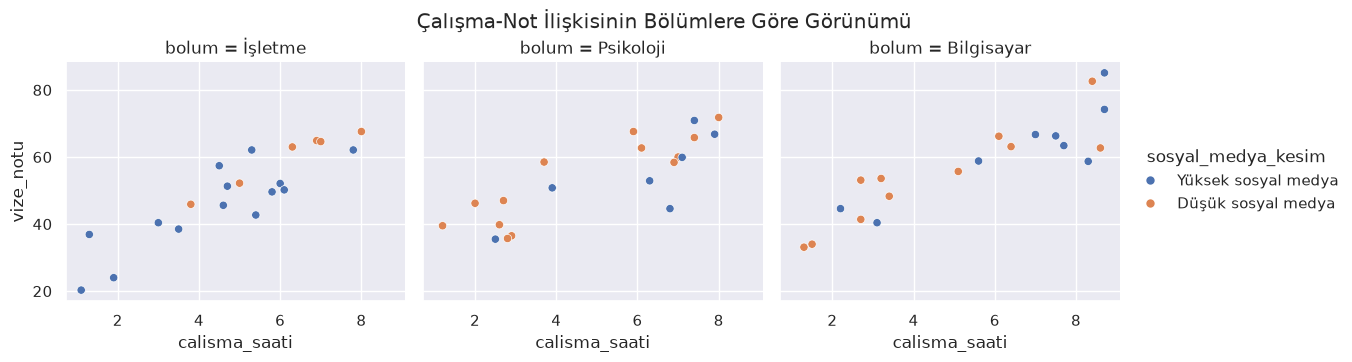

In [9]:
sns.relplot(data=ogrenci, x="calisma_saati", y="vize_notu",
             hue="sosyal_medya_kesim", col="bolum",
             height=3.5, aspect=1.1)
plt.suptitle("Çalışma-Not İlişkisinin Bölümlere Göre Görünümü", y=1.03)
plt.show()

Üç panel, aynı eksenler: bölümlere göre çalışma-not ilişkisi. Tüm panellerde eğilim yukarı yönlü — ilişki bölümden bağımsız görünüyor. Facet'lerin gücü budur: "her grup için aynı soruyu sorup cevapları yan yana koymak."

### 5) Kodu tamamla (TODO)

In [10]:
# TODO: ogrenci tablosuyla korelasyon ısı haritasını yeniden çiz,
# ama bu kez sosyal_medya_kesim hariç TÜM sayısal sütunlarla
# (kahve_fincan dahil) ve annot=True ile.
# Hangi iki değişken arasındaki ilişki şaşırtıcı? Bir cümlelik yorumunu hücreye yaz.

# kor2 = ...
# sns.heatmap(...)
# plt.show()

print("Kontrol: kahve-not korelasyonu:",
      round(ogrenci['kahve_fincan'].corr(ogrenci['vize_notu']), 2))

Kontrol: kahve-not korelasyonu: 0.79


Çözüm ve yorum "Cevaplar" bölümünde.

## 🧪 Deneyelim ve Gözlemleyelim

**Deney 1:** Isı haritasının paletini `cmap="viridis"` (sıralı) yaparak yeniden çiz. Okuma nasıl değişti? Negatif ve pozitif ilişkileri ayırmak kolaylaştı mı, zorlaştı mı? 2. dersin palet rejimleriyle gerekçelendir.

**Deney 2:** pairplot'a `corner=True` ekle. Figür ne kadar küçüldü, hangi bilgiler kayboldı? (Ayna hücreler aynı bilgiyi taşıyordu; peki üst üçgende var olan ama alt üçgende olmayan bir şey var mı?)

**Deney 3:** jointplot'ta `kind="hex"` dene (noktalar altıgen kovalara toplanır). 60 noktayılık veride işe yaradı mı? Peki 10.000 nokta olsaydı?

## 🧯 Bir Şeyler Ters Giderse

| Belirti | Olası neden | Çözüm |
|---|---|---|
| `ValueError` / bozuk pairplot | Metin sütunu pairplot'a girdi | `vars=[...]` ile sayısal sütunları açıkça seç |
| `TypeError` heatmap'te | Veri matris değil (ham DataFrame verildi) | Önce `.corr(numeric_only=True)` ya da `pivot_table` ile matris kur |
| `KeyError: 'sosyal_medya_kesim'` | Türetilen sütun hücresi çalıştırılmamış | Sütun türeten hücreyi yeniden çalıştır |
| Facet başlıkları üst üste biniyor | `suptitle` çakışması | `plt.suptitle(..., y=1.02)` ile yukarı taşı |
| Facet'ler çok küçük/çok büyük | `height`/`aspect` ayarsız | `height` panel yüksekliği, `aspect` genişlik oranıdır; deneyerek ayarla |
| Isı haritası "anlamsız renkler" | Sıralı palet + `center` belirtilmemiş | Ayrışan palet (`RdBu_r`) + `center=0` kullan |

> **İpucu:** Çok değişkenli grafiklerde sırayı bozmayın: önce korelasyon haritasıyla genel bakış, sonra şüphelendiğin çiftin jointplot'u, en son facet'lerle grup kırılımı. Her adım bir öncekinin sorusunu daraltır; hepsini birden istemek kalabalık grafik üretir.

## 🏋️ Kendin Dene

1. **Kahve zinciri:** 5. derstin satış tablosuyla `sehir`×`urun` kırılımında toplam adeti gösteren bir ısı haritası çiz (`pivot_table(index=..., columns=..., values=..., aggfunc="sum")` sonra `sns.heatmap(annot=True, fmt=",")`). Hangi şehir-hücre en sıcak?
2. **Anket:** 9. dersteki temiz anket verisiyle `pairplot` çiz (`yas`, `haftalik_kahve`, `memnuniyet`; `hue="sehir"`). Üç değişkenli bu matriste en belirgin örüntü ne?
3. **Karar:** İki ısı haritasını karşılaştır: korelasyon matrisi (sayı-sayı) ve pivot tablosu (kategori-kategori). İkisi ne bakımdan farklı sorulara cevap veriyor? İki cümleyle yaz.


## 🧠 Öğrendiklerini Kontrol Et

Cevaplar defterin sonundaki "Cevaplar" bölümünde. Önce kendin dene.

1. Korelasyon katsayısı hangi aralıkta değişir; +0.85, -0.4 ve 0.02 ne anlatır?
2. "Kahve içen öğrencinin notu yüksektir" bulgusunu alan biri "kahve notu yükseltir" sonucunu çıkarıyor. Neden hatalı? Doğru yorum ne olurdu?
3. Korelasyon ısı haritasında sıralı palet (ör. `viridis`) yerine ayrışan palet (ör. `RdBu_r`) ve `center=0` neden tercih edilir?
4. pairplot'un diyagonal hücreleri neden scatter değil de dağılım gösterir?
5. `hue` ile `col` (facet) arasındaki fark nedir? Hangisi "aynı eksende iç içe karşılaştırma", hangisi "yan yana panel karşılaştırması" kurar?
6. jointplot, hangi iki soruyu tek figürde birlikte yanıtlar?

## 🚀 Bağımsız Çalışma

- **İlişki dedektifi:** `ogrenci` tablosunda en güçlü üç ve en zayıf üç korelasyonu bul. Her biri için "neden böyle olabilir?" diye bir açıklama hipotezi yaz (doğrulamana gerek yok; mantıklı olmasına bak).
- **Alt grup merakı:** `relplot` ile `kahve_fincan`-`vize_notu` ilişkisini `col="sosyal_medya_kesim"` ile böl. Eğilim alt gruplarda farklı mı? Farklıysa bu ne anlatabilir? (İpucu: "Simpson yanılgısı" diye bir kavram var; merak edip araştırabilirsin.)

## 📚 Daha Fazlasını Öğrenmek

- seaborn ilişkisel grafikler: https://seaborn.pydata.org/tutorial/relational.html
- seaborn kategorik grafikler: https://seaborn.pydata.org/tutorial/categorical.html

İngilizcedir; kodlar doğrudan çalıştırılabilir.

## ✅ Kısa Özet

- Korelasyon matrisi + ısı haritası, çok değişkenli verinin ilk haritasıdır; ayrışan palet ve `center=0` ile okunur.
- İlişki, neden demek değildir: kahve-not ilişkisi, çalışma saatinin gölge değişken olmasından doğar.
- `pairplot` tüm çiftleri matris olarak verir; `vars` ile alt küme, `corner=True` ile yer tasarrufu, `diag_kind="kde"` ile yumuşak diyagonal.
- `jointplot` ilişkiyi ve iki kenar dağılımını tek figürde birleştirir; `kind="reg"` eğilim doğrusu ekler.
- `catplot`/`relplot` facet'lerle aynı grafiği alt gruplarda tekrarlar; `hue` iç içe, `col`/`row` yan yana karşılaştırma kurar.
- Çok değişkenlilik güç ister: neyi göstereceğine karar vermek, göstermekten önce gelir.

Sıradaki derste zaman boyutunu ekliyoruz: tarih verisiyle trend, mevsimsellik, hareketli ortalama ve animasyon.

---

[← Önceki ders: Seaborn Temelleri](09-Seaborn-Basics.ipynb) · [Sıradaki ders: Zaman Serileri Görselleştirme →](11-Time-Series.ipynb)

## Cevaplar

### Uygulama 5: tüm sütunlarla ısı haritası (TODO çözümü)

```python
kor2 = ogrenci[["calisma_saati", "uyku_saati", "sosyal_medya_saati",
                "kahve_fincan", "vize_notu"]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(kor2, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            fmt=".2f", linewidths=0.5)
plt.title("Tüm Sayısal Değişkenlerin Korelasyonu")
plt.show()
```

Şaşırtıcı bulgu: `kahve_fincan` ile `vize_notu` arasındaki güçlü pozitif ilişki. Yorum: kahve notu doğrudan yükseltmiyor; kahve tüketimi çalışma saatiyle birlikte arttığı için (kahve-calisma korelasyonu yüksek) gölge bir ilişki görüyoruz.

### Kontrol Et 1

-1 ile +1 arasında. +0.85: güçlü pozitif ilişki (ikisi birlikte artıyor). -0.4: orta düzey negatif ilişki (biri artarken diğeri azalıyor). 0.02: pratikte ilişki yok.

### Kontrol Et 2

Hatalı, çünkü korelasyon nedensellik göstermez. Doğru yorum: "kahve tüketimi yüksek olan öğrencilerde not da yüksek eğiliminde; bu, kahve içmenin etkisinden değil, büyük olasılıkla kahve ile birlikte artan çalışma saatinden kaynaklanıyor." Deney yapılmadan (her şeyi eşit tutup yalnız kahveyi değiştirmeden) neden söylenemez.

### Kontrol Et 3

Korelasyonun iki zıt yönü (negatif/pozitif) vardır ve ortası (0) "ilişki yok" noktasıdır. Ayrışan palet ortayı nötr yapıp iki ucu zıt renklere boyar; `center=0` bu eşlemeyi sabitler. Sıralı palet ise "daha büyük = daha koyu" der ve negatif-pozitif ayrımını yok eder.

### Kontrol Et 4

Diyagonalde çift, değişkenin kendisiyle eşleşir; bu "ilişki" anlamsız olur. O hücrede her değişkenin tek değişkenli dağılımı gösterilir — matrisin asıl amacı olan çift ilişkilerinin yanına değişkenlerin kendi profilleri de konur.

### Kontrol Et 5

`hue` aynı eksende kategorileri renkle iç içe koyar (hızlı karşılaştırma, kalabalık riski). `col`/`row` her kategori için ayrı panel açar (temiz karşılaştırma, yer ister). İç içe karşılaştırma `hue`, yan yana panel karşılaştırması `col` kurar.

### Kontrol Et 6

"Bu iki değişken birlikte mi hareket ediyor?" (ilişki) ve "her biri tek başına nasıl dağılıyor?" (marjinal dağılımlar).

### İpuçları

**Kendin Dene:** Pivot tabloda `fmt=","` yerine tam sayılar için `fmt=".0f"` gerekebilir. Korelasyon matrisi "değişkenler birlikte mi hareket ediyor?" der; pivot tablosu "hangi kategori kesişiminde değer büyük?" der — biri ilişki, öbürü kesişim sorusudur.
